In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(os.path.join(os.getcwd(), "..", "src")))
import numpy as np, sympy as sp
from IPython.display import Image, display, Markdown
sp.init_printing(use_unicode=True)
def show(path):
    p = path[0] if isinstance(path, tuple) else path
    display(Image(filename=p))


# 12. Parameter sweeps

Sweeps over $H$ and $M_{pl}$ (scaling $\Delta_t^2\propto H^2/M_{pl}^2$), over Bogoliubov-rotated initial states, and over the start time of the leading-WKB initial condition.
The last is an *exploratory observation with an exact explanation*: leading-WKB initial data at finite $x_{start}$ is a Bogoliubov state with $|\beta|=1/(2x_{start}^2)$,
and the numerical power ratio equals the exact prediction to $\sim10^{-10}$.

In [2]:
from desitter_perturbations.spectra import parameter_sweeps as ps
r = ps.sweep_H_Mpl(); print("max |numeric/predicted - 1|:", np.abs(r["numeric"]/r["predicted"] - 1).max())
b = ps.sweep_bogoliubov(); print("max |numeric - predicted| (Bogoliubov):", np.abs(b["numeric"] - b["predicted"]).max())
rows = ps.sweep_x_start()
for xs, ratio, pred, beta in zip(rows["x_start"], rows["ratio"], rows["predicted"], rows["abs_beta"]):
    print(f"x_start {xs:6.0f}  P/P_BD {ratio:.10f}  predicted {pred:.10f}  |beta| {beta:.3e}  1/(2x^2) {1/(2*xs**2):.3e}")

max |numeric/predicted - 1|: 2.198108361994855e-11


max |numeric - predicted| (Bogoliubov): 5.042410933242536e-11


x_start      5  P/P_BD 0.9722605649  predicted 0.9722605649  |beta| 2.000e-02  1/(2x^2) 2.000e-02
x_start     10  P/P_BD 1.0031974713  predicted 1.0031974713  |beta| 5.000e-03  1/(2x^2) 5.000e-03
x_start     20  P/P_BD 0.9982447249  predicted 0.9982447249  |beta| 1.250e-03  1/(2x^2) 1.250e-03
x_start     50  P/P_BD 1.0003489895  predicted 1.0003489895  |beta| 2.000e-04  1/(2x^2) 2.000e-04
x_start    100  P/P_BD 1.0000495947  predicted 1.0000495946  |beta| 5.000e-05  1/(2x^2) 5.000e-05
x_start    200  P/P_BD 0.9999869745  predicted 0.9999869744  |beta| 1.250e-05  1/(2x^2) 1.250e-05
x_start    500  P/P_BD 1.0000022429  predicted 1.0000022429  |beta| 2.000e-06  1/(2x^2) 2.000e-06
x_start   1000  P/P_BD 0.9999996316  predicted 0.9999996316  |beta| 5.000e-07  1/(2x^2) 5.000e-07


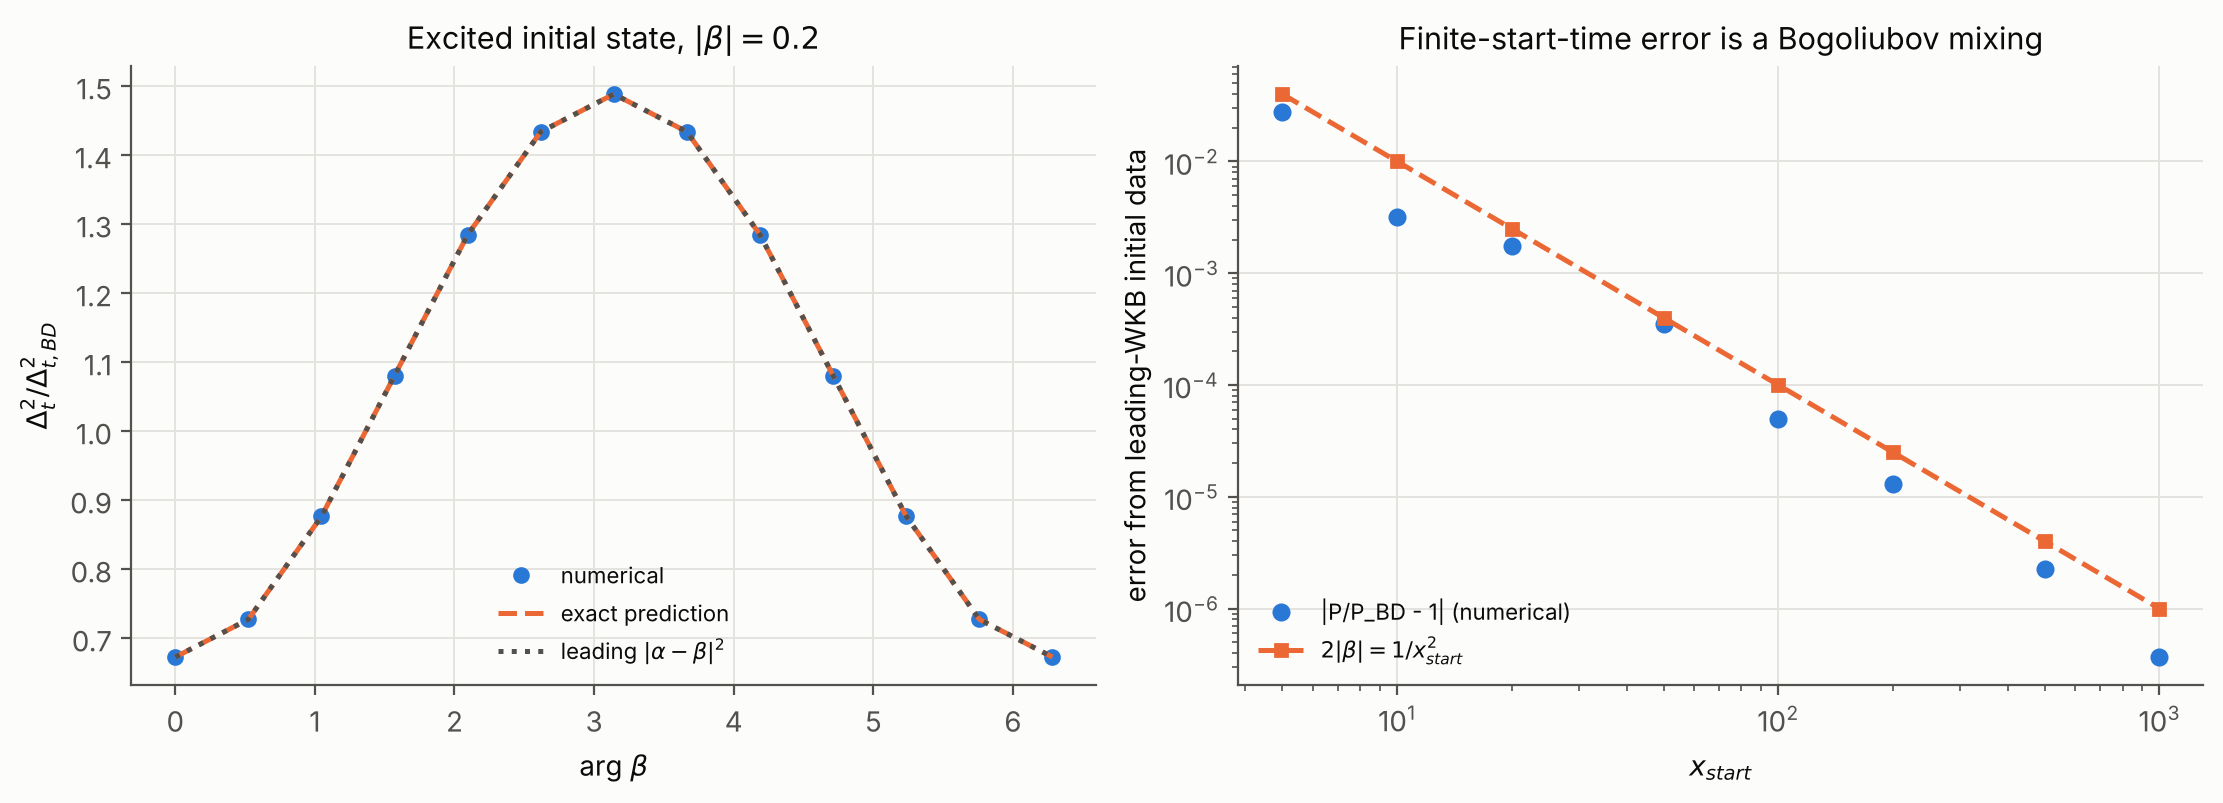

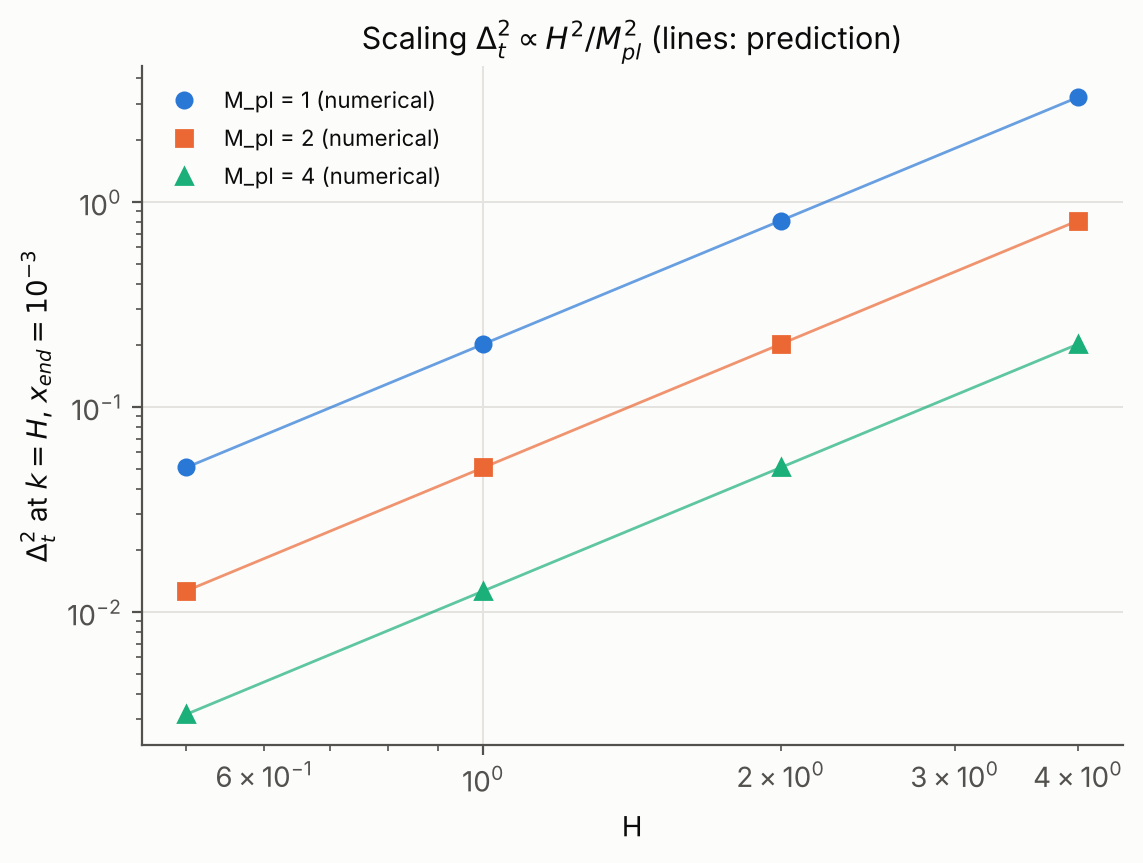

In [3]:
from desitter_perturbations.visualization import spectrum_plots as sp_
show(sp_.plot_bogoliubov_and_start()); show(sp_.plot_scaling_H_M())

In [4]:
import csv, os
path = os.path.join("..", "data", "generated", "sweep_x_start.csv")
print(open(path).read() if os.path.exists(path) else "run scripts/run_parameter_sweeps.py first")

x_start,ratio,predicted,abs_beta
5.000000000000e+00,9.722605649301e-01,9.722605649286e-01,2.000000000000e-02
1.000000000000e+01,1.003197471276e+00,1.003197471271e+00,5.000000000000e-03
2.000000000000e+01,9.982447248941e-01,9.982447248834e-01,1.250000000000e-03
5.000000000000e+01,1.000348989507e+00,1.000348989488e+00,2.000000000001e-04
1.000000000000e+02,1.000049594651e+00,1.000049594629e+00,5.000000000001e-05
2.000000000000e+02,9.999869744516e-01,9.999869744331e-01,1.250000000002e-05
5.000000000000e+02,1.000002242898e+00,1.000002242905e+00,2.000000000104e-06
1.000000000000e+03,9.999996315511e-01,9.999996316111e-01,4.999999999404e-07

